In [1]:

%pip install iterative-stratification scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

# Cell 1: Imports and configuration

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from iterstrat.ml_stratifiers import (
    MultilabelStratifiedShuffleSplit
)

ROOT = Path.cwd().parent

PROCESSED_DIR = ROOT / "data" / "processed"

MANIFEST_PATH = PROCESSED_DIR / "vindr_300_image_manifest.csv"
MASK_DIR = PROCESSED_DIR / "masks_256"
IMAGE_DIR = PROCESSED_DIR / "images_256"

CLASS_NAMES = [
    "Aortic enlargement",
    "Cardiomegaly",
    "Pleural thickening",
    "Pulmonary fibrosis",
    "Lung Opacity"
]

RANDOM_STATE = 42

print("Project root:", ROOT)
print("Manifest:", MANIFEST_PATH)
print("Image directory:", IMAGE_DIR)
print("Mask directory:", MASK_DIR)
print("Classes:", CLASS_NAMES)


Project root: c:\Users\johnm\chest-xray-ai-annotation
Manifest: c:\Users\johnm\chest-xray-ai-annotation\data\processed\vindr_300_image_manifest.csv
Image directory: c:\Users\johnm\chest-xray-ai-annotation\data\processed\images_256
Mask directory: c:\Users\johnm\chest-xray-ai-annotation\data\processed\masks_256
Classes: ['Aortic enlargement', 'Cardiomegaly', 'Pleural thickening', 'Pulmonary fibrosis', 'Lung Opacity']


In [3]:

# Cell 2: Load manifest and audit mask coverage

manifest = pd.read_csv(MANIFEST_PATH)

print("Manifest shape:", manifest.shape)
print("Unique images:", manifest["image_id"].nunique())

audit_results = []

for _, row in manifest.iterrows():

    image_id = str(row["image_id"])

    mask_path = MASK_DIR / f"{image_id}.npy"

    if not mask_path.exists():
        raise FileNotFoundError(
            f"Missing mask: {image_id}"
        )

    mask = np.load(mask_path)

    result = {"image_id": image_id}

    for channel, class_name in enumerate(CLASS_NAMES):

        # Image-level label
        image_label = int(row[class_name])

        # Whether this mask channel contains positive pixels
        mask_positive = int(
            np.any(mask[:, :, channel] > 0)
        )

        result[f"label_{class_name}"] = image_label
        result[f"mask_{class_name}"] = mask_positive

        result[f"pixels_{class_name}"] = int(
            mask[:, :, channel].sum()
        )

    audit_results.append(result)

audit_df = pd.DataFrame(audit_results)

print("\nMask audit completed.")
print("Images audited:", len(audit_df))

display(audit_df.head())


Manifest shape: (300, 13)
Unique images: 300

Mask audit completed.
Images audited: 300


,image_id,label_Aortic enlargement,mask_Aortic enlargement,pixels_Aortic enlargement,label_Cardiomegaly,mask_Cardiomegaly,pixels_Cardiomegaly,label_Pleural thickening,mask_Pleural thickening,pixels_Pleural thickening,label_Pulmonary fibrosis,mask_Pulmonary fibrosis,pixels_Pulmonary fibrosis,label_Lung Opacity,mask_Lung Opacity,pixels_Lung Opacity
0,690a74b4ebf969fbadc5ad0a1187968d,1,1,1622,1,1,6242,1,1,1035,1,1,756,0,0,0
1,db0409f17482d968dc350ae12a91d913,1,1,576,0,0,0,1,1,1452,0,0,0,0,0,0
2,e1a4dd4c30b1757eafb095021def4d63,1,1,716,1,1,3731,1,1,850,0,0,0,0,0,0
3,c399b71d7f853206cdf9bfa916252b4d,1,1,1833,1,1,3685,0,0,0,0,0,0,0,0,0
4,fcbe95aa17720d5caa68e24f4f664040,1,1,1476,0,0,0,0,0,0,0,0,0,0,0,0


In [4]:

# Cell 3: Compare image labels with mask presence

summary = []

for class_name in CLASS_NAMES:

    label_col = f"label_{class_name}"
    mask_col = f"mask_{class_name}"

    label_positive = int(audit_df[label_col].sum())
    mask_positive = int(audit_df[mask_col].sum())

    mismatches = int(
        (audit_df[label_col] != audit_df[mask_col]).sum()
    )

    summary.append({
        "Finding": class_name,
        "Positive image labels": label_positive,
        "Non-empty masks": mask_positive,
        "Mismatched images": mismatches
    })

coverage_df = pd.DataFrame(summary)

display(coverage_df)

coverage_df.to_csv(
    PROCESSED_DIR / "vindr_300_mask_coverage_audit.csv",
    index=False
)

print("\nCoverage audit saved.")


,Finding,Positive image labels,Non-empty masks,Mismatched images
0,Aortic enlargement,218,218,0
1,Cardiomegaly,163,163,0
2,Pleural thickening,146,146,0
3,Pulmonary fibrosis,123,123,0
4,Lung Opacity,108,108,0



Coverage audit saved.


In [5]:

# Cell 4: Multi-label stratified train/validation/test split

# Extract multi-label target matrix
X = manifest["image_id"].astype(str).values

y = manifest[CLASS_NAMES].values.astype(int)

# First split: 70% training, 30% temporary
split_1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=RANDOM_STATE
)

train_idx, temp_idx = next(
    split_1.split(X, y)
)

# Second split: divide temporary data equally
# 15% validation and 15% testing overall
X_temp = X[temp_idx]
y_temp = y[temp_idx]

split_2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=RANDOM_STATE
)

val_temp_idx, test_temp_idx = next(
    split_2.split(X_temp, y_temp)
)

val_idx = temp_idx[val_temp_idx]
test_idx = temp_idx[test_temp_idx]

# Create split dataframes
train_df = manifest.iloc[train_idx].copy()
val_df = manifest.iloc[val_idx].copy()
test_df = manifest.iloc[test_idx].copy()

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))


Training images: 213
Validation images: 43
Testing images: 44
Total: 300


,Finding,Train,Validation,Test,Total
0,Aortic enlargement,153,32,33,218
1,Cardiomegaly,114,23,26,163
2,Pleural thickening,102,22,22,146
3,Pulmonary fibrosis,86,18,19,123
4,Lung Opacity,76,16,16,108


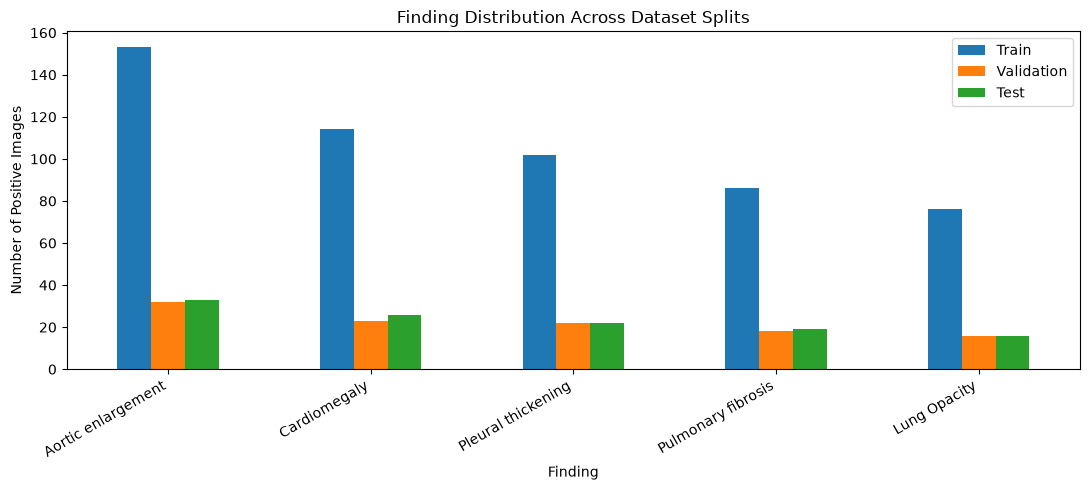

In [6]:

# Cell 5: Compare class distributions across splits

split_summary = []

for class_name in CLASS_NAMES:

    split_summary.append({
        "Finding": class_name,
        "Train": int(train_df[class_name].sum()),
        "Validation": int(val_df[class_name].sum()),
        "Test": int(test_df[class_name].sum()),
        "Total": int(manifest[class_name].sum())
    })

split_summary_df = pd.DataFrame(split_summary)

display(split_summary_df)

# Visualize the distribution
split_summary_df.set_index("Finding")[
    ["Train", "Validation", "Test"]
].plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Finding Distribution Across Dataset Splits")
plt.ylabel("Number of Positive Images")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [7]:

# Cell 6: Check image-level separation

train_ids = set(train_df["image_id"].astype(str))
val_ids = set(val_df["image_id"].astype(str))
test_ids = set(test_df["image_id"].astype(str))

print("Train-validation overlap:", len(train_ids & val_ids))
print("Train-test overlap:", len(train_ids & test_ids))
print("Validation-test overlap:", len(val_ids & test_ids))

all_ids = train_ids | val_ids | test_ids

print("\nUnique images across splits:", len(all_ids))

assert len(train_ids & val_ids) == 0
assert len(train_ids & test_ids) == 0
assert len(val_ids & test_ids) == 0
assert len(all_ids) == 300

print("\nSUCCESS: No image-level data leakage detected!")


Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

Unique images across splits: 300

SUCCESS: No image-level data leakage detected!


In [ ]:

# Cell 7: Save reproducible split manifests

train_path = PROCESSED_DIR / "train_manifest.csv"
val_path = PROCESSED_DIR / "validation_manifest.csv"
test_path = PROCESSED_DIR / "test_manifest.csv"

train_df.to_csv(train_path, index=False)
val_df.to_csv(val_path, index=False)
test_df.to_csv(test_path, index=False)

print("Saved:")
print(train_path)
print(val_path)
print(test_path)


Saved:
c:\Users\johnm\chest-xray-ai-annotation\data\processed\train_manifest.csv
c:\Users\johnm\chest-xray-ai-annotation\data\processed\validation_manifest.csv
c:\Users\johnm\chest-xray-ai-annotation\data\processed\test_manifest.csv


: 